# Homework 11


**Concepts covered:**

pandas `DataFrame`s: grouping data, querying `DataFrame`s, joining multiple `DataFrame`s, sampling.

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.


**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.

## Shared Imports

Do not install or use any additional modules.
Installing additional modules may result in an autograder failure resulting in zero points for some or all problems.

In [1]:
# shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.close("all")


**Note: This assignment is partially manually graded, so please allow some time for you to get your final scores.**

**Review Problem 1**

**Concept:** *`DataFrame`: initialization, line plots.*

**Task:**


Using the Starbucks stock dataset:

1. Load the `SBUX.csv` dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Create a line plot showing both the `high` and `low` prices over time.

Your plot should include:

* both high and low columns plotted together
* a title
* a key


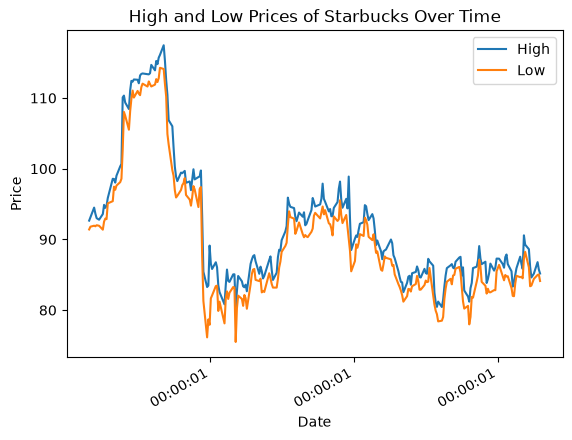

In [2]:
# Your Solution
df_sbux = pd.read_csv("SBUX.csv")

# 1. Convert the column to date and set it as the index
df_sbux["date"] = pd.to_datetime(df_sbux["date"])
df_sbux.set_index("date", inplace=True)

# 2. Plot the daily max min
df_sbux[["high", "low"]].plot(title="High and Low Prices of Starbucks Over Time")

plt.ylabel("Price")
plt.xlabel("Date")
plt.legend(["High", "Low"])
plt.show()


Review Problem 2

**Concept:** *`DataFrame`: initialization, descriptive statistics, histogram.*

**Task:**

Using the `SBUX.csv` dataset:

1. Load the dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Compute the **daily return** of the stock using the `close` column (percentage change).
4. Display the **descriptive statistics** of the daily returns.
5. Create a **histogram** of the daily returns using 25 bins.
6. Identify **outliers** where the return falls outside of **mean ± 3 standard deviations**.
7. Print:
    *  the upper and lower bounds
    * the number of values above and below these bounds
    * the list of outlier values (sorted by date)


Descriptive Statistics of Daily Returns:
count    249.000000
mean      -0.000130
std        0.021601
min       -0.112162
25%       -0.011336
50%        0.000107
75%        0.011323
max        0.112812
Name: pct_change, dtype: float64


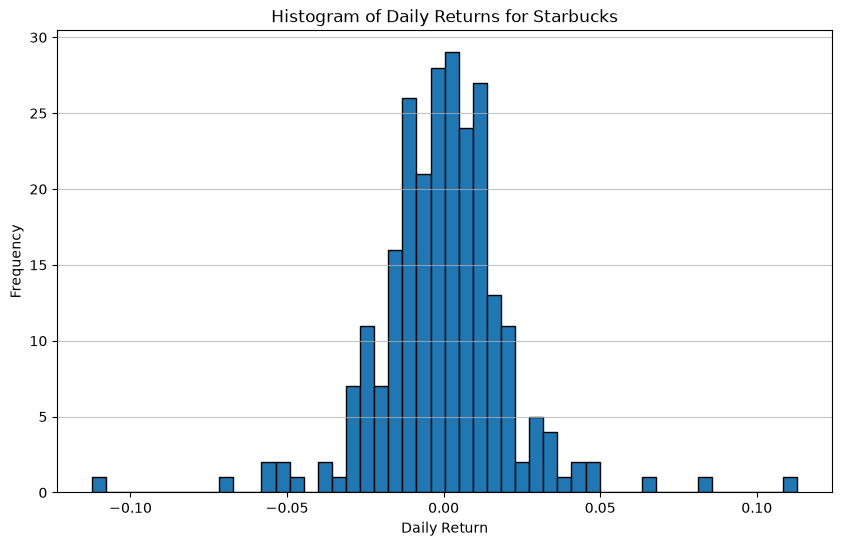

Upper Bound for Outliers: 0.06467188888830804
Lower Bound for Outliers: -0.06493212818695372
Number of values above the upper threshold: 3
Number of values below the lower threshold: 2
Outliers (sorted by date):
                               pct_change
date                                     
1970-01-01 00:00:01.738161000    0.081366
1970-01-01 00:00:01.743687000   -0.112162
1970-01-01 00:00:01.743773400   -0.069794
1970-01-01 00:00:01.744205400    0.112812
1970-01-01 00:00:01.747056600    0.066874


In [3]:
# Your Solution
# For number 1 and 2 already set in DataFrame df_sbux, and converted the date column to datetime and set it as the index.
# using same dataframe df_sbux, 
# percentage change in closing price from one day to the next
df_sbux["pct_change"] = df_sbux["close"].pct_change() 
# removing the first row which will be NaN after pct_change
#df_sbux = df_sbux.iloc[1:]
df_sbux= df_sbux.dropna(subset=["pct_change"])

# descriptive statistics of daily retuns

print("Descriptive Statistics of Daily Returns:")
print(df_sbux["pct_change"].describe())

# Histogram of daily returns
plt.figure(figsize=(10, 6))
plt.hist(df_sbux["pct_change"], bins=50, edgecolor='black')
plt.title("Histogram of Daily Returns for Starbucks")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.grid(axis='y', alpha=0.75)
plt.show()

# Indentifying the outliers where the return falls outside of mean ± 3 standard deviations
mean_return = df_sbux["pct_change"].mean()
std_return = df_sbux["pct_change"].std()
# Above and below the mean ± 3 standard deviations
above_threshold = mean_return + 3 * std_return
below_threshold = mean_return - 3 * std_return

outliers = df_sbux[(df_sbux["pct_change"] > above_threshold) | (df_sbux["pct_change"] < below_threshold)]

# Print upper and lower bounds for outliers
print(f"Upper Bound for Outliers: {above_threshold}")
print(f"Lower Bound for Outliers: {below_threshold}")

# number of values above and below the thresholds
num_above = len(df_sbux[df_sbux["pct_change"] > above_threshold])
num_below = len(df_sbux[df_sbux["pct_change"] < below_threshold])
print(f"Number of values above the upper threshold: {num_above}")
print(f"Number of values below the lower threshold: {num_below}")

#list the outliers values sorted by date
print("Outliers (sorted by date):")
print(outliers.sort_index()[["pct_change"]])








Test case for problem 2

In [4]:
# Test Case:
# Test 1: data loaded correctly with a date time index and percentage change calculated
assert isinstance(df_sbux.index, pd.DatetimeIndex), "Index is not a DatetimeIndex"
assert "pct_change" in df_sbux.columns, "Percentage change column not found"    

# tese 2: daily reutns computed with pct_change and outliers identified correctly
assert not df_sbux["pct_change"].isnull().any(), "Percentage change contains NaN values"
assert len(outliers) > 0, "No outliers identified"

# test case 3: bounds are mean ± 3 std deviations and number of outliers above and below thresholds are correct
assert above_threshold == mean_return + 3 * std_return, "Upper bound for outliers is incorrect"
assert below_threshold == mean_return - 3 * std_return, "Lower bound for outliers is incorrect"
assert num_above == len(df_sbux[df_sbux["pct_change"] > above_threshold]), "Number of values above the upper threshold is incorrect"
assert num_below == len(df_sbux[df_sbux["pct_change"] < below_threshold]), "Number of values below the lower threshold is incorrect"

# test case 4: outliers counted correctly and sorted by date
assert outliers.equals(df_sbux[(df_sbux["pct_change"] > above_threshold) | (df_sbux["pct_change"] < below_threshold)]), "Outliers not identified correctly"
assert outliers.sort_index().equals(outliers.sort_values(by="date")), "Outliers not sorted by date correctly"



**Problem 3**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Load the dataset into a DataFrame named `df_weather`.
2. Convert the `datetime` column to a pandas datetime format and set it as the index.
3. Use the icon column as a categorical variable and group the data by `icon`.
4. Create a **pie chart** showing the count of each weather icon category.

Your chart should include:
* labels for each category
* a title



C:\Users\raul_\AppData\Local\Temp\ipykernel_8392\747425946.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_weather["datetime"] = pd.to_datetime(df_weather["datetime"])


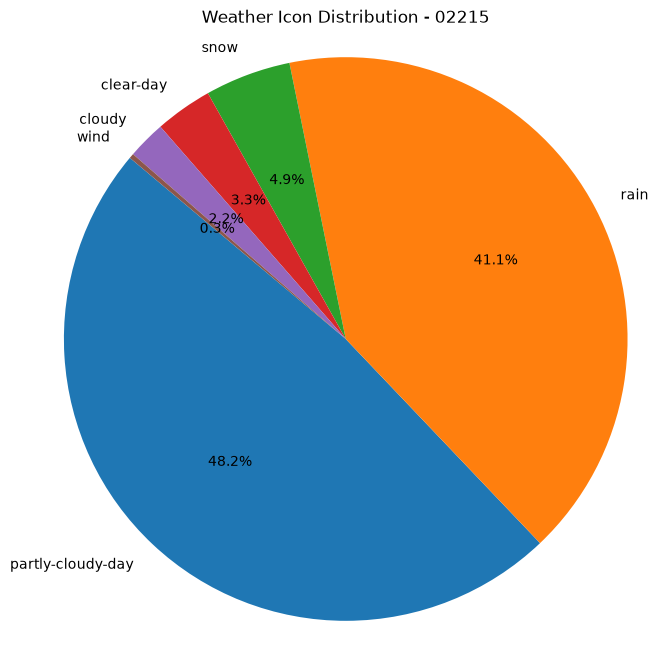

In [5]:
# Your Solution

df_weather = pd.read_csv("02215_weather.csv")

# 2. Convert the column to dattime and set it as the index
df_weather["datetime"] = pd.to_datetime(df_weather["datetime"])
df_weather.set_index("datetime", inplace=True)

# using icon column as categorical variable abd grouping by icon
df_weather["icon"]= df_weather["icon"].astype("category")

# create a pie chart of the weather icons
icon_counts = df_weather["icon"].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(icon_counts, labels=icon_counts.index, autopct='%1.1f%%', startangle=140)
plt.title("Weather Icon Distribution - 02215")
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()



**Problem 4**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a **histogram** of the `tempmax` column for each weather condition group.

Your plot should include:
* 25 bins
* transparency so overlapping distributions can be seen
* a legend
* a title


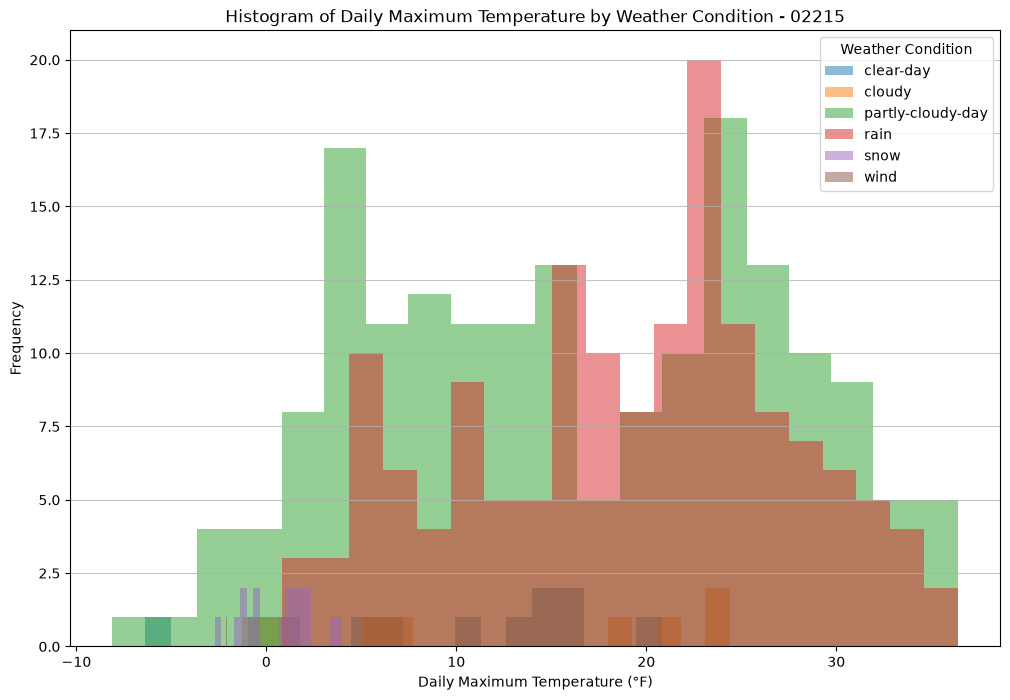

In [6]:
# Your Solution
# use icon based based grouping and create histogram of the tempmax column for each waether condition group
plt.figure(figsize=(12, 8))
for icon in df_weather["icon"].cat.categories:
    plt.hist(df_weather[df_weather["icon"] == icon]["tempmax"], bins=20, alpha=0.5, label=icon)
plt.title("Histogram of Daily Maximum Temperature by Weather Condition - 02215")
plt.xlabel("Daily Maximum Temperature (°F)")
plt.ylabel("Frequency")
plt.legend(title="Weather Condition")
plt.grid(axis='y', alpha=0.75)
plt.show()  



**Problem 5**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a histogram of the `precip` column for each weather condition group.

Your plot should include:

* 10 bins
* transparency so overlapping distributions can be seen
* a legend
* a title



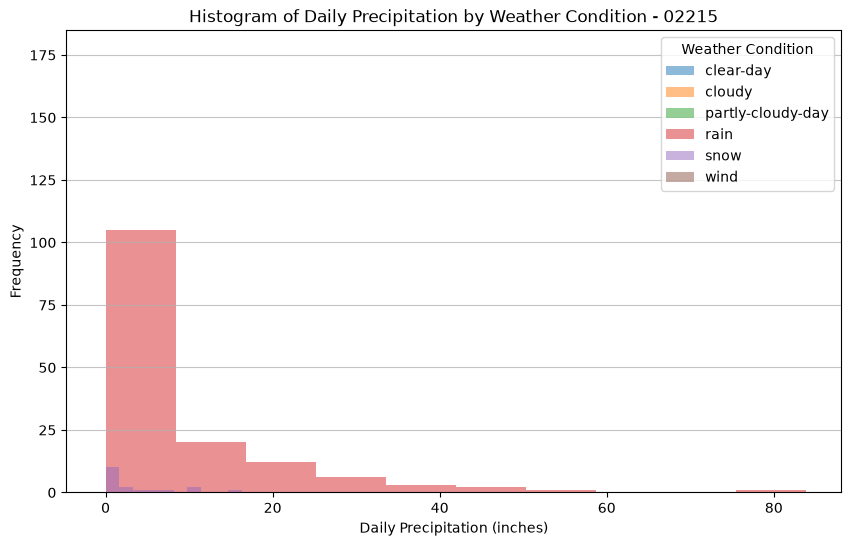

In [7]:
# Your Solution
# create histogram of the precip column iht 10 bins, transparency so overlapping distribution, a legend, a title
# for the icon column 

plt.figure(figsize=(10, 6))
for icon in df_weather["icon"].cat.categories:
    plt.hist(df_weather[df_weather["icon"] == icon]["precip"], bins=10, alpha=0.5, label=icon)
plt.title("Histogram of Daily Precipitation by Weather Condition - 02215")
plt.xlabel("Daily Precipitation (inches)")
plt.ylabel("Frequency")
plt.legend(title="Weather Condition")
plt.grid(axis='y', alpha=0.75)
plt.show()  



**Problem 6**

**Concept:** *Grouping Data, plotting*


**Task:**


Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Compute the **mean** of the `tempmax` column for each weather condition group.
3. Create a **bar chart** to display the mean maximum temperature for each group.


Your plot should include:

* one bar for each weather icon category
* a title



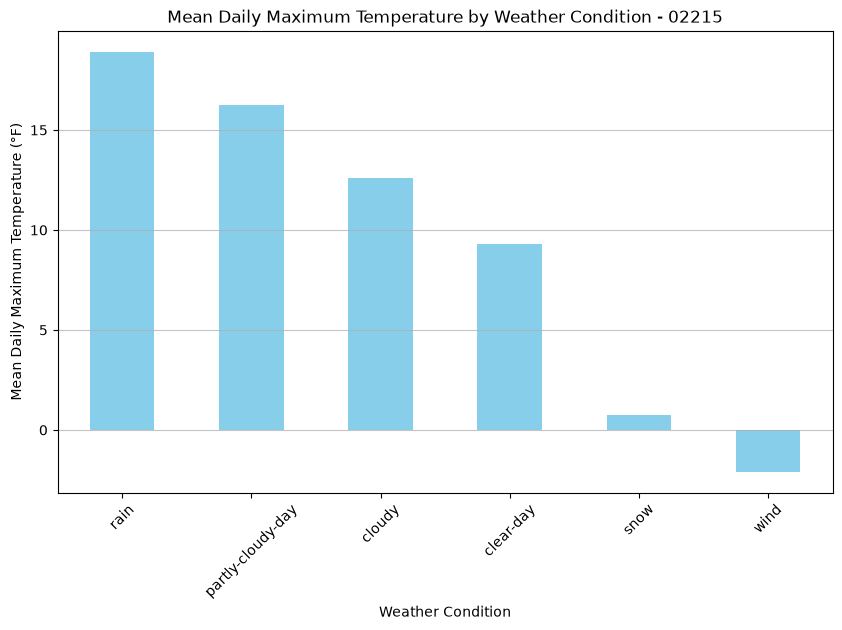

In [8]:
# Your Solution
# use icon column as categorical variable and grouping by icon, compute mean of the tempmax. create a bar chart . one bar for each eather icon, a title 
df_tempmax_mean = df_weather.groupby("icon")["tempmax"].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
df_tempmax_mean.plot(kind='bar', color='skyblue')
plt.title("Mean Daily Maximum Temperature by Weather Condition - 02215")
plt.xlabel("Weather Condition")
plt.ylabel("Mean Daily Maximum Temperature (°F)")
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.75)
plt.show()



**Problem 7**

**Concept:** *Grouping data, descriptive statistics*


**Task:**

Using the `02215_weather.csv` dataset:

1. Group the DataFrame by the `icon` column and store the result in a variable named `grouped_by_icon`.
2. Compute descriptive statistics for the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_statistics`.
3. Compute descriptive statistics for the `precip` column for each group and store the result in a variable named `grouped_precipitation_statistics`.
4. Compute the **mean** of the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_mean`.

Print all three results with clear labels:
* `"Tempmax grouped by conditions"`
* `"Precipitation grouped by conditions"`
* `"Mean of tempmax grouped by conditions"`


In [9]:
# Your Solution

# group the DataFrame by the icon and store the result in a variable named grouped_icons
grouped_icons = df_weather.groupby("icon")

# compute descriptive statistics for the tempmax column column for each group and store result in varilable named grouped_tempmax_statistics
grouped_tempmax_statistics = grouped_icons["tempmax"].describe()

# compute descriptive statistics for the precip column for each group and store result in variable named grouped_precipitation_statistics
grouped_precipitation_statistics = grouped_icons["precip"].describe()

# compute the mean of the tempmax column for each group and store result in variable named grouped_tempmax_mean
grouped_tempmax_mean = grouped_icons["tempmax"].mean()

# print all three results with clear labels
print("Tempmax grouped by conditions")
print(grouped_tempmax_statistics)
print("\nPrecipitation grouped by conditions")
print(grouped_precipitation_statistics)
print("\nMean of tempmax grouped by conditions")
print(grouped_tempmax_mean)     




Tempmax grouped by conditions
                   count       mean        std  min    25%    50%     75%  \
icon                                                                        
clear-day           12.0   9.316667   8.230965 -6.4   4.15  12.10  15.225   
cloudy               8.0  12.575000  10.423565 -1.3   4.95  13.05  21.350   
partly-cloudy-day  176.0  16.246023  10.533554 -8.1   7.20  15.65  25.000   
rain               150.0  18.904000   8.498037  0.8  12.60  19.90  24.600   
snow                18.0   0.750000   1.805628 -2.7  -0.65   1.25   1.775   
wind                 1.0  -2.100000        NaN -2.1  -2.10  -2.10  -2.100   

                    max  
icon                     
clear-day          20.8  
cloudy             24.4  
partly-cloudy-day  36.4  
rain               36.4  
snow                4.0  
wind               -2.1  

Precipitation grouped by conditions
                   count      mean        std    min      25%     50%  \
icon                               

QUERYING

The following data frame will be used in several questions.


In [10]:
# starter code
df_voter_data = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv", low_memory=False)
df_voter_data.index = df_voter_data["Voter ID Number"]
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])


**Problem 8**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Determine the **total number of voters** and print the result.
2. Compute the count of voters in each **Party Affiliation** category.
3. Create a **pie chart** showing the distribution of voters by party affiliation.

Your plot should include:
* labels for each category
* a title that includes the total number of voters


Total number of voters: 58769


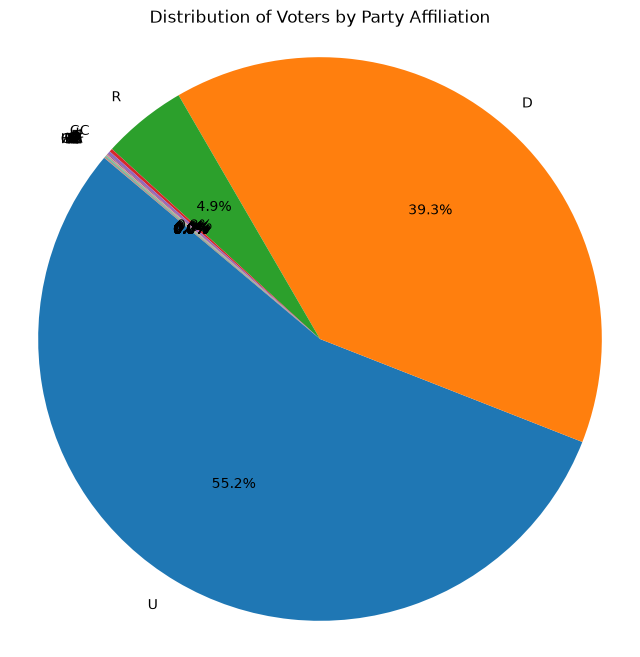

In [11]:
# Your Solution

# use df_voter_data determine the total number of voters and print the result
total_voters = len(df_voter_data)
print(f"Total number of voters: {total_voters}")    

# compute the count of voters in each Party Affiliation category
party_counts = df_voter_data["Party Affiliation"].value_counts()

#create a pie chart showing the distribution of voters by Party Affiliation
plt.figure(figsize=(8, 8))
plt.pie(party_counts, labels=party_counts.index, autopct='%1.1f%%', startangle=140)
plt.title("Distribution of Voters by Party Affiliation")
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()  



**Problem 9**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_older_voters` that includes only voters born **before January 1, 1950**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these older voters.

Your plot should include:
* labels for each category
* a title that includes the number of older voters


Total number of voters born before January 1, 1950: 9073


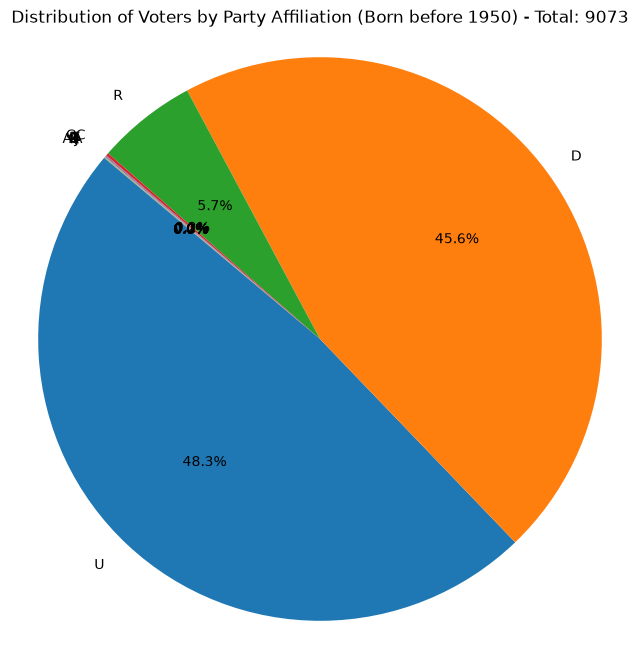

In [12]:
# Your Solution
# new DataFrame named df_older_voters that includes only voters born before January 1, 1950 using .query() method
df_older_voters = df_voter_data.query("`Date of Birth` < '1950-01-01'")

# print the total number of voter in this new DataFrame
total_older_voters = len(df_older_voters)
print(f"Total number of voters born before January 1, 1950: {total_older_voters}")

# conputing the count of voters in each Party Affiliation category for this new DataFrame
older_party_counts = df_older_voters["Party Affiliation"].value_counts()

# creating pie chart showing the distribution of voters by Party Affiliation for this new DataFrame, labes for each category. title that includes the number of older voters
plt.figure(figsize=(8, 8))
plt.pie(older_party_counts, labels=older_party_counts.index, autopct='%1.1f%%', startangle=140)
plt.title(f"Distribution of Voters by Party Affiliation (Born before 1950) - Total: {total_older_voters}")
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()




**Problem 10**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_younger_voters` that includes only voters born **after January 1, 2000**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these Younger voters.

Your plot should include:
* labels for each category
* a title that includes the number of younger voters


Total number of voters born after January 1, 2000: 5099


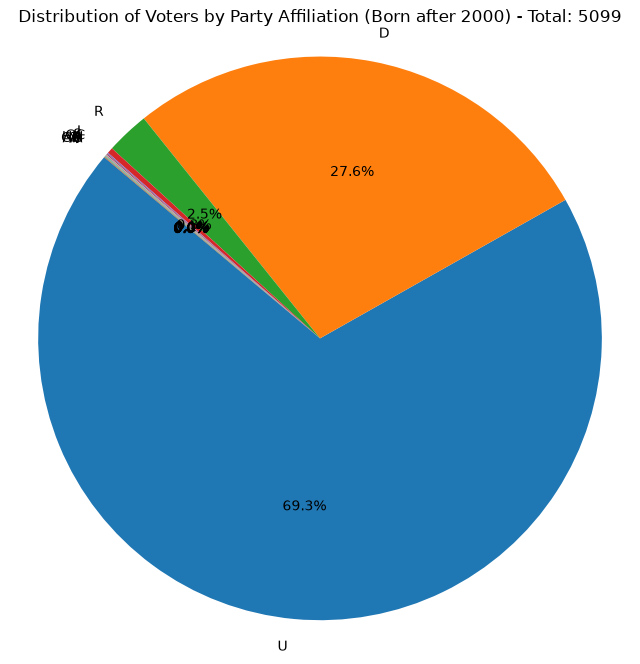

In [13]:
# Your Solution
# use df_voter_data to create a new DataFrame named df_recent_voters that includes only voters born after January 1, 2000 using .query() method
df_recent_voters = df_voter_data.query("`Date of Birth` > '2000-01-01'")

# print the total number of voter in this new DataFrame
total_recent_voters = len(df_recent_voters)
print(f"Total number of voters born after January 1, 2000: {total_recent_voters}")

# compute the count of voters in each Party Affiliation category for this new DataFrame
recent_party_counts = df_recent_voters["Party Affiliation"].value_counts()

# creating pie chart showing the distribution of voters by Party Affiliation for this new DataFrame, labes for each category. title that includes the number of recent voters
plt.figure(figsize=(8, 8))
plt.pie(recent_party_counts, labels=recent_party_counts.index, autopct='%1.1f%%', startangle=140)
plt.title(f"Distribution of Voters by Party Affiliation (Born after 2000) - Total: {total_recent_voters}")
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()




**Problem 11**

**Concept:** *Querying `DataFrame`s and graphing*



**Task:**

Using the `df_voter_data` DataFrame:
1. Identify all columns related to elections:
    * Select columns whose names contain the letter `"v"` but do **not** contain `"score"`
    * Store the result in a variable named `election_columns`

2. Compute the **voting participation percentage** for each election among all voters:
    * Store the result in a variable named `d1`
    * **Hint:** To calculate participation
        * Use `.sum()` on a column to count how many voters participated
        * Divide by the total number of voters using `len(df)`
        * Multiply by 100 to convert to a percentage

3. Create a filtered DataFrame named `df_high_voter_score`:
    * Include only voters with `voter_score >= 4`
    * Print the number of voters in this group

4. Compute the **voting participation percentage** for this group:
    * Store the result in a variable named `d2`

5. Create a filtered DataFrame named `df_unenrolled`:
    * Include only voters with `"Party Affiliation" == "U "`
    * Print the number of voters in this group

6. Compute the voting participation percentage for this group:
    * Store the result in a variable named `d3`

7. Combine the results into a new DataFrame named `d`:
    * Index should be the election columns
    * Columns should be:
        * `"all voters"`
        * `"high-propensity voters"`
        * `"unenrolled voters"`

8. Create a **bar chart** from this combined DataFrame.

Your plot should include:
* a title
* a key

Number of voters with voter_score >= 4: 15245
Number of unenrolled voters: 0


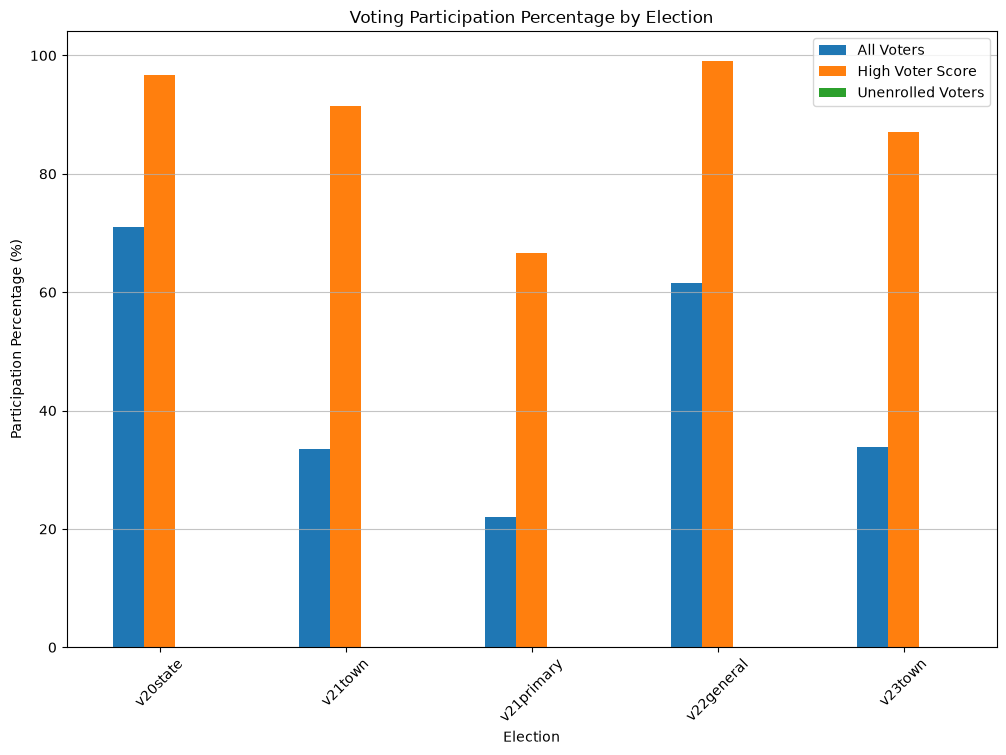

In [14]:
# Your Solution

# use df_voter_data identify all columns related to election, names containing "v" don't contain "score"
election_columns = [col for col in df_voter_data.columns if "v" in col and "score" not in col]

# computing the voting participation percentage for each election among all voters, result in d1, use .sum(), dividing total number len(df), multiple by 100 to get percentage
d1 = (df_voter_data[election_columns].sum() / len(df_voter_data)) * 100

# creating filtered dataframe named df_high_voter_score include voter_score >= 4, print number of voters in this group
df_high_voter_score = df_voter_data[df_voter_data["voter_score"] >= 4]
num_high_voter_score = len(df_high_voter_score)
print(f"Number of voters with voter_score >= 4: {num_high_voter_score}")    

# computing voting participation percentage for this group variable d2
d2 = (df_high_voter_score[election_columns].sum() / num_high_voter_score) * 100

# creating named df_unenrolled include with "Party Affiliation" == "U", print number of voters in this group
df_unenrolled = df_voter_data[df_voter_data["Party Affiliation"] == "U"]
num_unenrolled = len(df_unenrolled)
print(f"Number of unenrolled voters: {num_unenrolled}")

# computing voting participation percentage for this group variable d3
d3 = (df_unenrolled[election_columns].sum() / num_unenrolled) * 100

# combine results in d, indexed by election name, columns for all voters, high voter score, and unenrolled voters
d = pd.DataFrame({
    "All Voters": d1,
    "High Voter Score": d2,
    "Unenrolled Voters": d3
})  

# creating a bar chart with combined results, title, key
d.plot(kind='bar', figsize=(12, 8))
plt.title("Voting Participation Percentage by Election")
plt.xlabel("Election")
plt.ylabel("Participation Percentage (%)")
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.75)



**Problem 12**

**Concept:** *Joining `DataFrame`s*


**Task:**

You are given two DataFrames:
* `submissions`, which contains student IDs and their homework submission IDs
* `grades`, which contains homework grades indexed by submission ID

Using these DataFrames:
1. Inspect both DataFrames by printing them.
2. Join the `submissions` DataFrame with the `grades` DataFrame:
    * Match the `hw1_submission` column in `submissions` with the index of `grades`
    * Store the result in a variable named `result`
3. Update the index of the resulting DataFrame:
    * Set the index to the `student_id` column
4. Create a new DataFrame named `result_df`:
    * Remove the `student_id` column
5. Print the final DataFrame


Starter code:

In [15]:
# STARTER CODE:
submissions = pd.DataFrame(data={"student_id": ["U100", "U101", "U102", "U103", "U104"],
                        "hw1_submission": ["c1325", "b231", "a512", "e9999", "d8234"]})

grades = pd.DataFrame(index=["a512", "b231", "c1325", "d8234", "e9999"],
                        data={"hw1_grade": [0.99, 0.50, 0.62, 0.78, 1.00]} )


In [16]:
# Your Solution

# inspecting both submissions and grades DataFrames and printing the results
print("Submissions DataFrame:")
print(submissions)
print("\nGrades DataFrame:")
print(grades)

# join submissions and grades, match the hw1_submission column in submissions with the index of grades, store in named result
result = submissions.join(grades, on="hw1_submission")
print("\nResult DataFrame:")
print(result)

# updating the index of the result setting index to student_id column
result.set_index("student_id", inplace=True)
print("\nResult DataFrame with student_id as index:")
print(result)



Submissions DataFrame:
  student_id hw1_submission
0       U100          c1325
1       U101           b231
2       U102           a512
3       U103          e9999
4       U104          d8234

Grades DataFrame:
       hw1_grade
a512        0.99
b231        0.50
c1325       0.62
d8234       0.78
e9999       1.00

Result DataFrame:
  student_id hw1_submission  hw1_grade
0       U100          c1325       0.62
1       U101           b231       0.50
2       U102           a512       0.99
3       U103          e9999       1.00
4       U104          d8234       0.78

Result DataFrame with student_id as index:
           hw1_submission  hw1_grade
student_id                          
U100                c1325       0.62
U101                 b231       0.50
U102                 a512       0.99
U103                e9999       1.00
U104                d8234       0.78


**Problem 13**

**Concept:** *Joining `DataFrame`s*



**Task:**

You are given two datasets:
* `design_materials.tsv`, which contains materials and the quantity required per bed
* `material_costs.tsv`, which contains the cost per unit for each material

Using these datasets:
1. Load both datasets from the provided `.tsv` files using the correct separator.
2. Merge the two DataFrames:
    * Join on the `material` column
    * Store the result in a variable named `df_costs`
3. Create a new column named `cost`:
    * Compute it as:

      **quantity_per_bed × unit_cost**
4. Print the resulting DataFrame

In [17]:
# Your Solution
# load both datasets fro the design_materials and material_costs file using the correct separator(tab), store in named DataFrames
df_design_materials = pd.read_csv("design_materials.tsv", sep="\t")
df_material_costs = pd.read_csv("material_costs.tsv", sep="\t")

# merge 2 dataframes on material column and store in df_costs
df_costs = pd.merge(df_design_materials, df_material_costs, on="material")

# creating a new column named cost as quantity_per_bed X unit_cost, and store in df_costs
df_costs["cost"] = df_costs["quantity_per_bed"] * df_costs["unit_cost"] 

# print the resulting DataFrame df_costs
print("Merged DataFrame with Cost Calculation:")
print(df_costs)



Merged DataFrame with Cost Calculation:
          design                    material  quantity_per_bed  unit_cost  \
0  4' x 4' x 18"                2" x 6" x 4'                20       5.92   
1  4' x 4' x 18"  8" x 8" x 16" Cinder Block                12       3.53   
2  4' x 8' x 18"                2" x 6" x 4'                 6       5.92   
3  4' x 8' x 18"                2" x 6" x 8'                14       7.62   
4  4' x 8' x 18"  8" x 8" x 16" Cinder Block                24       3.53   
5  4' x 4' x 12"                2" x 6" x 4'                16       5.92   
6  4' x 4' x 12"  8" x 8" x 16" Cinder Block                12       3.53   
7  4' x 8' x 12"                2" x 6" x 4'                 2       5.92   
8  4' x 8' x 12"                2" x 6" x 8'                12       7.62   
9  4' x 8' x 12"  8" x 8" x 16" Cinder Block                24       3.53   

     cost  
0  118.40  
1   42.36  
2   35.52  
3  106.68  
4   84.72  
5   94.72  
6   42.36  
7   11.84  
8   

**Problem 14**

**Concept:** *joining `DataFrame`s*


**Task:**

You are given three stock datasets:
* BAC
* GM
* SBUX

Using these datasets:
1. Load each dataset into separate DataFrames:
    * `df_bac`, `df_gm`, and `df_sbux`
2. Convert the `date` column in each DataFrame to pandas datetime format and set it as the index.
3. Create a new DataFrame named `df_stock_prices`:
    * Use the index from `df_bac`
    * Add the following columns:
        * `"bac"` from `df_bac["close"]`
        * `"gm"` from `df_gm["close"]`
        * `"sbux"` from `df_sbux["close"]`
4. Create a **line plot** showing the stock prices over time.

Your plot should include:
* all three stocks on the same chart
* a title

                                     bac         gm       sbux
date                                                          
1970-01-01 00:00:01.735828200  44.290001  51.369999  92.169998
1970-01-01 00:00:01.735914600  44.810001  51.770000  92.580002
1970-01-01 00:00:01.736173800  45.400002  53.529999  93.129997
1970-01-01 00:00:01.736260200  46.080002  51.980000  92.839996
1970-01-01 00:00:01.736346600  46.209999  51.000000  92.599998


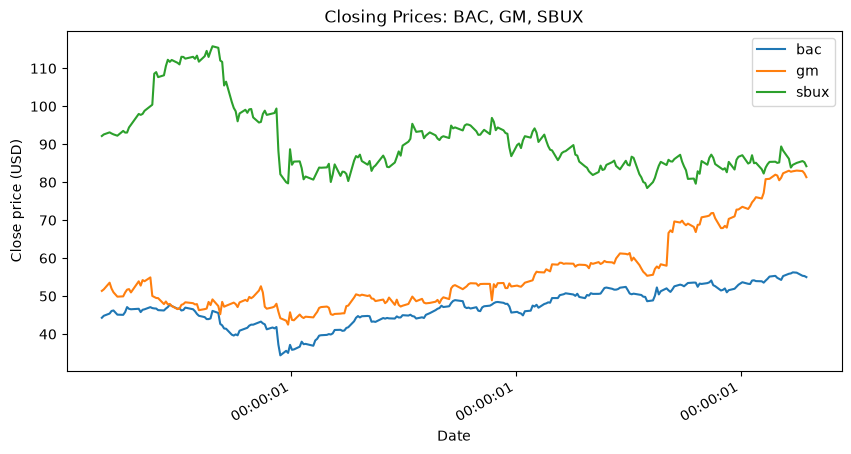

In [18]:
# Your Solution
# Loading dataset df_bac, df_gm, and df_sbux from the respective CSV files, 
df_bac = pd.read_csv("BAC.csv")
df_gm = pd.read_csv("GM.csv")
df_sbux = pd.read_csv("SBUX.csv")

# converting the date column in each dataframeto pandas datetime format and setting it as the index
df_bac["date"] = pd.to_datetime(df_bac["date"])
df_bac.set_index("date", inplace=True)
df_gm["date"] = pd.to_datetime(df_gm["date"])
df_gm.set_index("date", inplace=True)
df_sbux["date"] = pd.to_datetime(df_sbux["date"])
df_sbux.set_index("date", inplace=True)

# creating new DataFrames named df_stock_prices, use index from df_bac and add bac from df_bac["close"], gm from df_gm["close"], sbux from df_sbux["close"]

df_stock_prices = pd.DataFrame(index=df_bac.index)
df_stock_prices["bac"] = df_bac["close"]
df_stock_prices["gm"] = df_gm["close"]
df_stock_prices["sbux"] = df_sbux["close"]
print(df_stock_prices.head())

# creating line plot showing stock price over time, all 3 stocks on same chart, title   
line_plot = df_stock_prices.plot(figsize=(10, 5), title="Closing Prices: BAC, GM, SBUX")
line_plot.set_xlabel("Date")
line_plot.set_ylabel("Close price (USD)")
plt.show()  




**Problem 15**

**Concept:** *joining `DataFrame`s*


**Task:**

Using the `df_stock_prices` DataFrame from **Problem 14**:
1. Compute the **relative prices** of each stock:
    * Divide all values by the first row of the DataFrame
    * Store the result in a variable named `df_stock_prices_relative`
2. Create a **line plot** of the relative prices.

Your plot should include:
* all three stocks on the same chart
* a title

                                    bac        gm      sbux
date                                                       
1970-01-01 00:00:01.735828200  1.000000  1.000000  1.000000
1970-01-01 00:00:01.735914600  1.011741  1.007787  1.004448
1970-01-01 00:00:01.736173800  1.025062  1.042048  1.010416
1970-01-01 00:00:01.736260200  1.040415  1.011875  1.007269
1970-01-01 00:00:01.736346600  1.043351  0.992797  1.004665


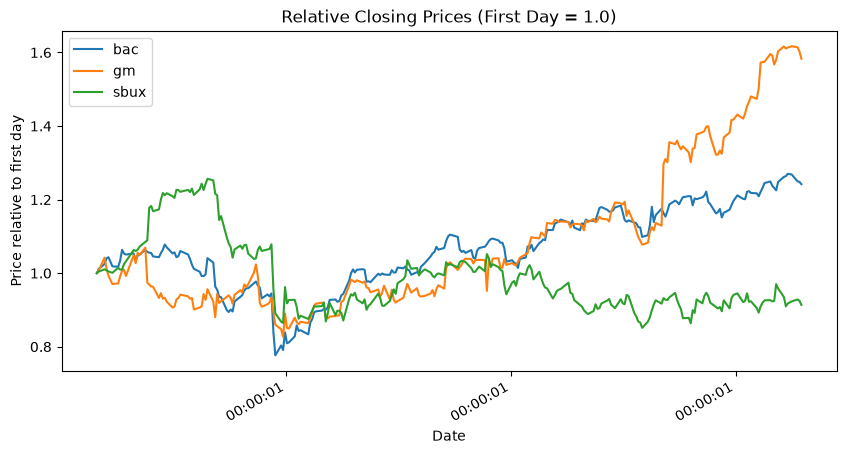

In [19]:
# Your Solution
# use df_stock_prices, compute relative prices of each stock, divide all values by the first row, store the result df_stock_price_relative
df_stock_prices_relative = df_stock_prices/ df_stock_prices.iloc[0]
print(df_stock_prices_relative.head())

# ploting line plot of the relative prices, all three stocks on the same chart and tiles
line_plot = df_stock_prices_relative.plot(figsize=(10, 5), title="Relative Closing Prices (First Day = 1.0)")
line_plot.set_xlabel("Date")
line_plot.set_ylabel("Price relative to first day")
plt.show() 

